**<font color=lightblue>PyTorch CNN on Yale Face (each image size is 168 x 192)</font>**



參考卷積 convolution 的矩陣運算：http://www.songho.ca/dsp/convolution/convolution2d_example.html


![Convolution](https://i.stack.imgur.com/9OZKF.gif)

<font size = 3>[動畫來源](https://pub.towardsai.net/image-classification-with-neural-network-21a75cebb067)</font>

***<font color=khaki>Import packages</font>***

In [12]:
import torch
import pickle
import numpy as np
import torchvision
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

***<font color=khaki>Load and prepare data</font>***

- 可使用原始影像大小 168 x 192，或是直接縮小成 84 x 96。
- 或使用 facenet 擷取並轉換成 160 x 160 的影像，或轉換成 84 x 84 的影像。

In [2]:
# open and read data/YaleFaces.pkl

with open('data/YaleFaces.pkl', 'rb') as f:
    data_dict = pickle.load(f)

X = data_dict['X']
y = data_dict['y']

# count the number of persons in the dataset
persons = list(set(y))
print("Number of persons:", len(persons))
    
test_size = 0.3
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size) # deafult test_size=0.25

# standaredize (may not be necessary or just scale to [0, 1]) the data for CNN
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test) # use the same scaler to transform test data
print("Data have been standardized.")

# convert to tensors for PyTorch CNN, and reshape to N x 1 x 192 x 168
X_train = torch.from_numpy(X_train).float()
y_train = torch.from_numpy(y_train).long()
X_train = X_train.reshape(-1, 1, 192, 168) # convert to N x 1 x 192 x 168 for CNN
X_test = torch.from_numpy(X_test).float()
y_test = torch.from_numpy(y_test).long()
X_test = X_test.reshape(-1, 1, 192, 168) # N x 1 x 192 x 168

# check shapes of data
print("X_train.shape:", X_train.shape)
print("y_train.shape:", y_train.shape)
print("X_test.shape:", X_test.shape)
print("y_test.shape:", y_test.shape)

# create dataloaders
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# print number of batches
print("Batch size:", batch_size)
print("Number of training batches:", len(train_loader))
print("Number of testing batches:", len(test_loader))

Number of persons: 38
Data have been standardized.
X_train.shape: torch.Size([1687, 1, 192, 168])
y_train.shape: torch.Size([1687])
X_test.shape: torch.Size([723, 1, 192, 168])
y_test.shape: torch.Size([723])
Batch size: 32
Number of training batches: 53
Number of testing batches: 23


*<font color=khaki>Define the network</font>*

![My image](picturesNet_structure.png)

註：當一個 5x5 卷積濾波器面對黑白圖像時，譬如輸入為 (1,192,168)，其中 1 代表黑白圖像的 1 個 channel。若輸入為彩色圖像，譬如輸入為 (3,192,168)，其中 3 代表色彩的 3 個 channels，其輸出會以 weighted sum 合成一個 channel，即 (1,xx,yy), xx, yy 視padding, stride 而定。

In [6]:
class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()
        
        self.conv1 = nn.Conv2d(1, 6, 5) # 1 input channel, 6 output channels, 5x5 square convolution
        self.conv2 = nn.Conv2d(6, 16, 5) # 6 input channel, 16 output channels, 5x5 square convolution
        # an affine operation: y = Wx + b
        self.fc1 = nn.Linear(16 * 45 * 39, 120)  # 4*4 from image dimension 
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 38) # 38 output classes

    def forward(self, x):
        
        x = F.max_pool2d(F.relu(self.conv1(x)), (2, 2)) # Max pooling over a (2, 2) window
        # If the size is a square, you can specify with a single number
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = torch.flatten(x, 1) # flatten all dimensions except the batch dimension
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        out = self.fc3(x)
        return out


device = "cuda:0" if torch.cuda.is_available() else "cpu"
print("Using {} device".format(device))

net = Net().to(device)
print(net)

Using cuda:0 device
Net(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=28080, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=38, bias=True)
)


*<font color=yellow>Use Torch Summary to see the details</font>*

In [7]:
from torchsummary import summary

summary(net, input_size=(1, 192, 168)) # input size is 1 x 192 x 168

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [-1, 6, 188, 164]             156
            Conv2d-2           [-1, 16, 90, 78]           2,416
            Linear-3                  [-1, 120]       3,369,720
            Linear-4                   [-1, 84]          10,164
            Linear-5                   [-1, 38]           3,230
Total params: 3,385,686
Trainable params: 3,385,686
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.12
Forward/backward pass size (MB): 2.27
Params size (MB): 12.92
Estimated Total Size (MB): 15.31
----------------------------------------------------------------


*<font color=khaki>Test to see the layer output for various settings</font>*

觀察並確認輸入圖像經過 Conv1、Conv2、MaxPool 後的尺寸變化，並與 Torch Summary 的輸出對照。

In [8]:
inData = torch.randn(128, 1, 192, 168) # sumulate 128 random 192 x 168 images with 1 channel

# layer 1
m = nn.Conv2d(1, 6, 5, stride=1, padding=0)
outData = m(inData)
print("Cov1 output shape:", outData.shape)
outData = F.max_pool2d(F.relu(outData), (2, 2))
print("MaxPool1 output shape:", outData.shape)

# layer 2
m = nn.Conv2d(6, 16, 5, stride=1)
outData = m(outData)
print("Cov2 output shape:", outData.shape)
outData = F.max_pool2d(F.relu(outData), 2)
print("MaxPool2 output shape:", outData.shape)

# start to enetr the NN part
outData = torch.flatten(outData, 1)
print("Flatten output shape:", outData.shape)

m = nn.Linear(16 * 45 * 39, 120)
outData = m(outData)
print("FC1 output shape:", outData.shape)

m = nn.Linear(120, 84)
outData = m(outData)
print("FC2 output shape:", outData.shape)

m = nn.Linear(84, 38)
outData = m(outData)
print("FC3 output shape:", outData.shape)
# check the output
print(outData[1,:])


Cov1 output shape: torch.Size([128, 6, 188, 164])
MaxPool1 output shape: torch.Size([128, 6, 94, 82])
Cov2 output shape: torch.Size([128, 16, 90, 78])
MaxPool2 output shape: torch.Size([128, 16, 45, 39])
Flatten output shape: torch.Size([128, 28080])
FC1 output shape: torch.Size([128, 120])
FC2 output shape: torch.Size([128, 84])
FC3 output shape: torch.Size([128, 38])
tensor([ 0.0332,  0.0370, -0.1442,  0.0462, -0.0008,  0.0373,  0.0589, -0.0112,
         0.0391,  0.0163, -0.0254, -0.0508, -0.0606,  0.1020,  0.0121,  0.0045,
         0.0633,  0.1030,  0.2307, -0.1734,  0.0841,  0.0234,  0.0963,  0.0506,
         0.0223,  0.1174,  0.1150,  0.0202, -0.1500,  0.1060, -0.0617,  0.0383,
        -0.0565,  0.0210, -0.0165, -0.0321,  0.0262,  0.0313],
       grad_fn=<SliceBackward0>)


*<font color=khaki>Take a look at the training image dataset</font>*

確認訓練圖像是否正確載入，並且圖像與標籤對應正確。

Shape of the first image: torch.Size([1, 192, 168])
Label of the first image: tensor(6)
The output shape of the network: (1, 38)
The output of the first image: tensor([[ 0.0366, -0.0141, -0.0749, -0.0005,  0.1147, -0.0964,  0.0425,  0.0889,
         -0.0349,  0.0954,  0.0123,  0.0415,  0.0348,  0.0931,  0.0887, -0.0532,
         -0.0154,  0.1053, -0.0229, -0.0341,  0.1497,  0.0840,  0.0259,  0.0798,
          0.0628, -0.1110, -0.0717,  0.0837, -0.0247, -0.0031, -0.0442, -0.0043,
          0.1299, -0.0955, -0.0822, -0.0648,  0.0166,  0.1341]],
       device='cuda:0')
The position of the maximum value: tensor([[20]], device='cuda:0')
The output as a numpy array: [[ 0.03662008 -0.01409921 -0.07489049 -0.00050446  0.11469486 -0.09636746
   0.04246198  0.08890894 -0.03489021  0.09538577  0.01225597  0.04146744
   0.03476204  0.09313668  0.0887377  -0.05324586 -0.01542761  0.10531799
  -0.02293221 -0.03411856  0.1496847   0.08399326  0.02594167  0.07976688
   0.06279444 -0.11104484 -0.071703

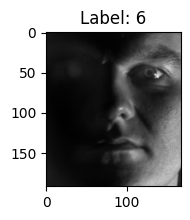

The image shape of the batch: torch.Size([32, 1, 192, 168])


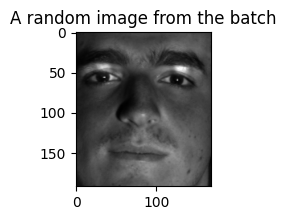

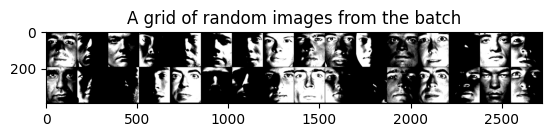

In [10]:
print("Shape of the first image:", train_dataset[0][0].shape) # the shape of the first image
print("Label of the first image:", train_dataset[0][1]) # the label of the first image

# send the first image to the network
inData = train_dataset[0][0].reshape(1, 1, 192, 168) 
outData = net(inData.to(device))
print("The output shape of the network:",outData.to("cpu").detach().numpy().shape) # the output shape of the first image
print("The output of the first image:", outData.data) # the output of the first image
print("The position of the maximum value:", outData.data.max(1, keepdim=True)[1]) # the position of the maximum value
print("The output as a numpy array:", outData.detach().cpu().numpy()) # convert the output to numpy array

# See the first image
npimg = train_dataset[0][0] # the first image
fig = plt.figure(figsize=(2, 2)) # set the figure size
plt.imshow(np.transpose(npimg, (1, 2, 0)), cmap='gray') # convert the image to numpy array and show it
plt.title("Label: {}".format(train_dataset[0][1])) # show the label as title
plt.show()

# get some random training images
dataiter = iter(train_loader) # an iterable object
images, labels = next(dataiter) # get the next batch
print("The image shape of the batch:", images.shape) # the shape of the batch

# show a single image
a_image = images[0]
a_image_ = np.transpose(a_image, (1, 2, 0))
fig = plt.figure(figsize=(2, 2)) # set the figure size
plt.imshow(a_image_, cmap='gray')
plt.title("A random image from the batch")
plt.show()

# show a grid of images
montage = torchvision.utils.make_grid(images, nrow=16) # make a grid of images with 16 images per row
# clip the pixel values to [0, 1] for display
montage = np.clip(montage, 0, 1)
plt.imshow(np.transpose(montage, (1, 2, 0)), cmap='gray')
plt.title("A grid of random images from the batch")
plt.show()


*<font color=yellow>Define a Loss function and optimizer</font>*

Let's use a Classification Cross-Entropy loss and SGD with momentum.



In [13]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)
# optimizer = optim.Adam(net2.parameters(), lr = 0.01) 

*<font color=yellow>Train the network</font>*

以下程式碼僅列出訓練過程中 loss 函數值的更新。可以嘗試加入訓練的準確值 accuracy。

In [15]:
epochs = 10
# set net to training mode
net.train()
for epoch in range(epochs):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(train_loader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data[0].to(device), data[1].to(device) # move to GPU if available
    
        # zero the parameter gradients
        optimizer.zero_grad()
        # forward --> backward --> optimize
        outputs = net(inputs) # forward pass
        loss = criterion(outputs, labels) # compute loss
        loss.backward() # compute gradients
        optimizer.step() # update weights

        # print statistics
        running_loss += loss.item()
        if i % 20 == 19:    # print every 20 mini-batches
            print(f'[epoch : {epoch + 1}, batch: {i + 1:5d}] loss: {running_loss / 20:.3f}')
            running_loss = 0.0

print('Finished Training')
print("The output shape of the network for the last batch:", outputs.shape)
print("The label shape for the last batch:", labels.shape)


[epoch : 1, batch:    20] loss: 0.365
[epoch : 1, batch:    40] loss: 0.300
[epoch : 2, batch:    20] loss: 0.276
[epoch : 2, batch:    40] loss: 0.258
[epoch : 3, batch:    20] loss: 0.458
[epoch : 3, batch:    40] loss: 0.696
[epoch : 4, batch:    20] loss: 0.330
[epoch : 4, batch:    40] loss: 0.238
[epoch : 5, batch:    20] loss: 0.147
[epoch : 5, batch:    40] loss: 0.148
[epoch : 6, batch:    20] loss: 0.131
[epoch : 6, batch:    40] loss: 0.103
[epoch : 7, batch:    20] loss: 0.115
[epoch : 7, batch:    40] loss: 0.111
[epoch : 8, batch:    20] loss: 0.077
[epoch : 8, batch:    40] loss: 0.113
[epoch : 9, batch:    20] loss: 0.084
[epoch : 9, batch:    40] loss: 0.091
[epoch : 10, batch:    20] loss: 0.101
[epoch : 10, batch:    40] loss: 0.056
Finished Training
The output shape of the network for the last batch: torch.Size([23, 38])
The label shape for the last batch: torch.Size([23])


*<font color=yellow>save our trained model for later use</font>*

做為再次訓練的起點或訓練完成後的使用狀態。

A .pth file in the context of PyTorch is a model checkpoint file that contains the learned weights of a trained neural network. The .pth extension stands for "PyTorch", indicating that the file is specifically meant to be loaded with PyTorch.

In [ ]:
PATH = './YaleFace_net.pt' # .pth will collide with the PyTorch JIT
torch.save(net.state_dict(), PATH)

In [16]:
print(net.state_dict().keys())

odict_keys(['conv1.weight', 'conv1.bias', 'conv2.weight', 'conv2.bias', 'fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias', 'fc3.weight', 'fc3.bias'])


*<font color=yellow>Test the network on the test data</font>*

In [16]:
correct = 0
total = 0
net.eval() # set the network to evaluation mode
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad(): # deactivate autograd engine
    for data in test_loader:
        images, labels = data[0].to(device), data[1].to(device)
        # calculate outputs by running images through the network
        outputs = net(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs.data, 1) # get the position of the maximum value
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the {len(test_dataset)} test images: {100 * correct // total} %')

Accuracy of the network on the 723 test images: 87 %


*<font color=yellow>Test on a random batch</font>*

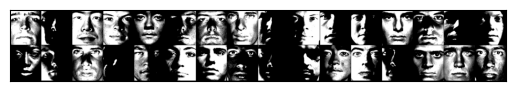

The predictions:
 {tensor([[17, 10,  1, 14, 30, 28, 28, 23,  2, 14, 16, 30, 21, 21, 34, 26],
        [20,  6, 23,  7, 36, 13, 24, 11, 28,  8, 30,  5, 16, 29, 31, 11]],
       device='cuda:0')}
Accuracy of the network on the 32 test images: 96.875 %


In [17]:
sample_idx = torch.randint(len(test_loader), size=(1,)).item()
dataiter = iter(test_loader)
for i in range(sample_idx): # randomly select a batch
    images, labels = next(dataiter)

# print test images
nrow = 16 # number of images per row
montage = torchvision.utils.make_grid(images, nrow=nrow)
img = np.transpose(montage.detach().cpu().numpy(), (1, 2, 0)) # convert to numpy array and transpose to H x W x C for imshow
img = np.clip(img, 0.0, 1.0)   # force valid imshow range
plt.imshow(img, cmap="gray", vmin=0.0, vmax=1.0)
plt.xticks([])
plt.yticks([])
plt.show()

# predict the labels
outputs = net(images.to(device))
_, predicted = torch.max(outputs, 1)
print("The predictions:\n", {predicted.reshape(batch_size // nrow, nrow)})

total = labels.size(0)
correct_rate = (predicted == labels.to(device)).sum().item() / total
print(f'Accuracy of the network on the {len(labels)} test images: {100 * correct_rate} %')


*<font color=yellow>Evaluate the model on test data</font>*

In [17]:
def test():
    # Test the model
    net2.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for images, labels in test_loader:
            test_output, last_layer = net2(images.to(device))
            pred_y = torch.max(test_output, 1)[1]
            correct += (pred_y == labels.to(device)).sum().item()
            total += labels.size(0)
            # accuracy = (pred_y == labels.to(device)).sum().item() / float(labels.size(0))
            pass
    accuracy = correct / total
    print(f'Test Accuracy of the model on the {len(test_dataset)} test images: %.2f' % accuracy)
    
    pass
test()

Test Accuracy of the model on the 14000 test images: 0.97
